# Лабораторная работа 1: Регрессия

**Цель работы:** Пройти полный цикл решения задачи регрессии: от первичного анализа данных и простого baseline до сравнения нескольких моделей и анализа результатов. Достичь качества $RMSE < 0.70$ на тестовой выборке.

Дополнительная метрика - MAE.

In [ ]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, PowerTransformer

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
RANDOM_STATE = 888

## 1. Знакомство с данными и первичный анализ

Загрузим локальные файлы `winequality-red.csv` и `winequality-white.csv` из текущей директории и объединим их в единый датасет. Добавим бинарный признак `is_red` (1 — красное вино, 0 — белое вино), так как органолептические и физико-химические свойства разных сортов заметно различаются.

In [3]:
df_red = pd.read_csv('winequality-red.csv', sep=';')
df_white = pd.read_csv('winequality-white.csv', sep=';')

df_red['is_red'] = 1
df_white['is_red'] = 0

df = pd.concat([df_red, df_white], ignore_index=True)

print(
    f'Размер красного вина: {df_red.shape[0]} строк, белого вина:'
    f' {df_white.shape[0]} строк'
)
print(
    f'Размер объединенного датасета: {df.shape[0]} строк, {df.shape[1]}'
    ' столбцов'
)
print(f'Количество пропусков в данных: {df.isna().sum().sum()}')
display(df.head())
display(df.describe().T[['count', 'mean', '50%', 'min', 'max', 'std']])

Размер красного вина: 1599 строк, белого вина: 4898 строк
Размер объединенного датасета: 6497 строк, 13 столбцов
Количество пропусков в данных: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


,count,mean,50%,min,max,std
fixed acidity,6497.0,7.215307,7.00000,3.80000,15.90000,1.296434
volatile acidity,6497.0,0.339666,0.29000,0.08000,1.58000,0.164636
citric acid,6497.0,0.318633,0.31000,0.00000,1.66000,0.145318
residual sugar,6497.0,5.443235,3.00000,0.60000,65.80000,4.757804
chlorides,6497.0,0.056034,0.04700,0.00900,0.61100,0.035034
free sulfur dioxide,6497.0,30.525319,29.00000,1.00000,289.00000,17.749400
total sulfur dioxide,6497.0,115.744574,118.00000,6.00000,440.00000,56.521855
density,6497.0,0.994697,0.99489,0.98711,1.03898,0.002999
pH,6497.0,3.218501,3.21000,2.72000,4.01000,0.160787
sulphates,6497.0,0.531268,0.51000,0.22000,2.00000,0.148806


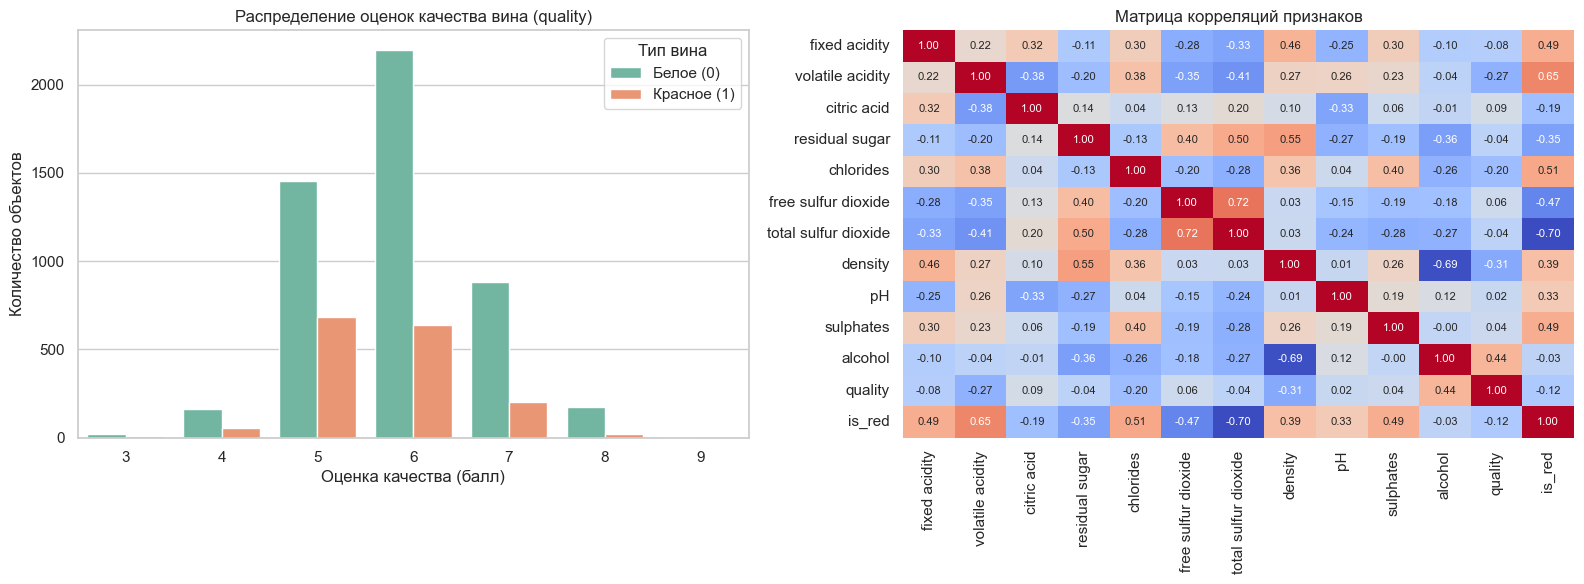

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.countplot(data=df, x='quality', hue='is_red', ax=axes[0], palette='Set2')
axes[0].set_title('Распределение оценок качества вина (quality)')
axes[0].set_xlabel('Оценка качества (балл)')
axes[0].set_ylabel('Количество объектов')
axes[0].legend(title='Тип вина', labels=['Белое (0)', 'Красное (1)'])

corr_matrix = df.corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    ax=axes[1],
    cbar=False,
    annot_kws={'size': 8},
)
axes[1].set_title('Матрица корреляций признаков')

plt.tight_layout()
plt.show()

### Выводы по первичному анализу данных:
1. **Масштаб данных и выбросы:** В датасете 6497 строк (1599 красного и 4898 белого вина), пропусков нет. Признаки измеряются в совершенно разных масштабах: например, плотность (`density`) держится около $0.99\text{–}1.04$, а общий диоксид серы (`total sulfur dioxide`) доходит до $440$. Кроме того, в остаточном сахаре (`residual sugar`) и диоксиде серы есть сильные выбросы (максимумы в десятки раз выше медианы). Значит, перед обучением линейной регрессии данные нужно будет нормализовать и отмасштабировать.
2. **Дисбаланс целевой переменной:** Оценки `quality` идут от 3 до 9 баллов, но распределены неравномерно — больше 75% всех вин получили средние оценки (5 или 6 баллов). Очень плохих (3–4) и отличных (8–9) вин в выборке мало, поэтому моделям будет трудно точно предсказывать такие крайние оценки.
3. **Главные зависимости (корреляции):**
   * Сильнее всего на оценку влияет **`alcohol`** ($r = 0.44$): чем выше градус, тем в среднем выше качество вина (крепкие вина обычно получаются из более спелого и качественного винограда). Этот признак точно будет самым важным для моделей.
   * Заметную отрицательную связь показывают **`density`** ($r = -0.31$) и **`volatile acidity`** (летучая кислотность, $r = -0.27$). Это логично: избыток летучих кислот дает неприятный запах уксуса и портит вкус вина.
   * Между самими признаками тоже есть сильные связи (мультиколлинеарность): например, чем больше спирта (`alcohol`), тем ниже плотность (`density`, $r = -0.69$), а свободный и общий диоксид серы тесно связаны друг с другом ($r = 0.72$). Чтобы линейную модель не «шатало» от зависимых признаков, для нее пригодится регуляризация (`Ridge`).

## 2. Подготовка выборок

Разделим данные на обучающую (`train`) и тестовую (`test`) части в соотношении 80% / 20%, зафиксировав `random_state = 42` и применив стратификацию по целевой переменной `quality`.

In [5]:
X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f'Размер обучающей выборки (Train): {X_train.shape[0]} объектов')
print(f'Размер тестовой выборки (Test):  {X_test.shape[0]} объектов')

Размер обучающей выборки (Train): 5197 объектов
Размер тестовой выборки (Test):  1300 объектов


### Обоснование разбиения данных:
* Данные разделены в пропорции **80% на обучение (5197 строк)** и **20% на тест (1300 строк)** с фиксацией `random_state = 42` для воспроизводимости. Такого объема `train` достаточно для обучения нелинейных моделей, а 1300 объектов в `test` дают устойчивую оценку итоговой ошибки.
* Использовано стратифицированное разбиение (`stratify=y`), чтобы сохранить одинаковые пропорции редких оценок качества (особенно баллов 3 и 9) в обеих выборках.
* Тестовая выборка используется только один раз для финального сравнения моделей. Если многократно подбирать параметры или признаки, ориентируясь на метрику на `test`, возникнет неявная утечка данных (переобучение под тестовую выборку), и оценка качества станет завышенной.

## 3. Метрики и baseline

* **MAE (Mean Absolute Error)** показывает, на сколько баллов `quality` в среднем по модулю ошибается модель. Все отклонения учитываются линейно с одинаковым весом, поэтому метрика легко интерпретируется и слабо реагирует на единичные выбросы.
* **RMSE (Root Mean Squared Error)** — корень из среднеквадратичной ошибки. Так как перед усреднением ошибки возводятся в квадрат, крупные промахи штрафуются непропорционально сильно (например, ошибка в 1 балл дает вклад 1, а ошибка в 3 балла — уже 9).
* Из-за квадратичного штрафа значение RMSE всегда не меньше MAE ($RMSE \ge MAE$). Заметная разница между этими двумя метриками у одной модели сигнализирует о том, что в предсказаниях встречаются отдельные грубые ошибки (выбросы).

В качестве простого константного **baseline** используем среднее арифметическое `quality`, посчитанное строго по обучающей выборке (`y_train.mean()`). Именно среднее значение математически минимизирует сумму квадратов отклонений, а значит, является оптимальной константой для метрики RMSE.

In [6]:
results = {}


def evaluate_model(name, y_true, y_pred):
  rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
  mae = float(mean_absolute_error(y_true, y_pred))
  results[name] = {'RMSE': rmse, 'MAE': mae}
  print(f'{name} -> RMSE: {rmse:.4f}, MAE: {mae:.4f}')
  return rmse, mae


baseline_const = y_train.mean()
y_pred_base = np.full(len(y_test), baseline_const)

print(f'Константа baseline (среднее на train): {baseline_const:.4f}')
evaluate_model('Baseline', y_test, y_pred_base);

Константа baseline (среднее на train): 5.8182
Baseline -> RMSE: 0.8738, MAE: 0.6861


## 4. Линейная регрессия (Linear Regression)

1. Сначала обучим обычную линейную регрессию на исходных признаках (до и после `StandardScaler`), чтобы исследовать коэффициенты и влияние масштабирования.
2. На исходных 12 признаках линейная регрессия дает $RMSE = 0.7280$, так как не способна уловить нелинейные взаимодействия химических свойств. Чтобы преодолеть порог $RMSE < 0.70$, применим нормализацию скошенных распределений (`PowerTransformer`) и сгенерируем **полиномиальные признаки 3-й степени (`PolynomialFeatures(degree=3)`, как советовали в чате)** с линейной моделью (`Ridge` и классической `LinearRegression` с отбором признаков).

Обычная линейная регрессия (12 признаков) -> RMSE: 0.7280, MAE: 0.5678
Polynomial LinearRegression (OLS, k=150)  -> RMSE: 0.6991
Linear Regression -> RMSE: 0.6790, MAE: 0.5291


,Признак,Веса БЕЗ масштабирования,Веса С масштабированием (StandardScaler)
7,density,-107.254294,-0.322959
3,residual sugar,0.064502,0.308646
10,alcohol,0.215202,0.255823
1,volatile acidity,-1.461996,-0.242319
11,is_red,0.308885,0.133536
0,fixed acidity,0.087201,0.112144
9,sulphates,0.744676,0.109287
6,total sulfur dioxide,-0.001602,-0.090906
8,pH,0.548259,0.088102
5,free sulfur dioxide,0.004882,0.086140


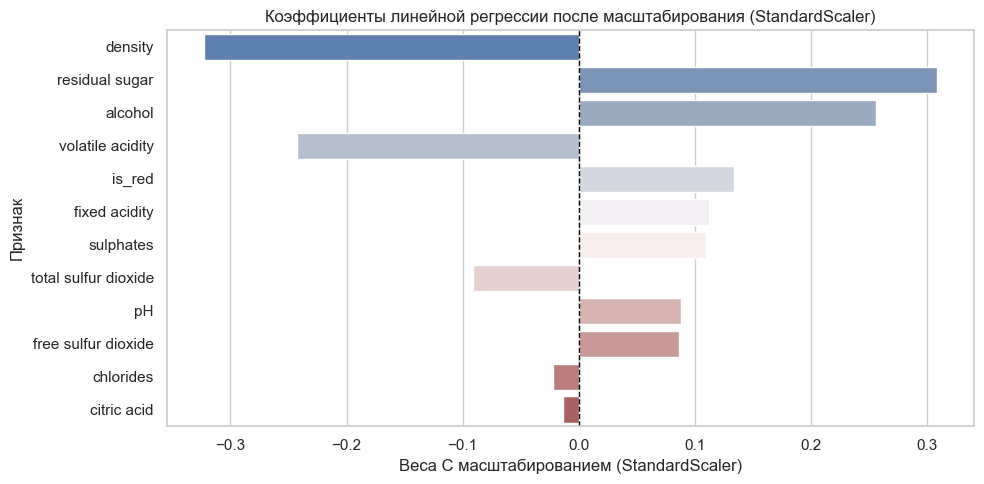

In [7]:
lr_unscaled = LinearRegression().fit(X_train, y_train)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_simple = LinearRegression().fit(X_train_scaled, y_train)
y_pred_lr_simple = lr_simple.predict(X_test_scaled)
print(
    'Обычная линейная регрессия (12 признаков) -> RMSE:'
    f' {np.sqrt(mean_squared_error(y_test, y_pred_lr_simple)):.4f}, MAE:'
    f' {mean_absolute_error(y_test, y_pred_lr_simple):.4f}'
)

lr_poly_ols = Pipeline([
    ('pt', PowerTransformer()),
    ('poly', PolynomialFeatures(degree=3, include_bias=False)),
    ('selector', SelectKBest(score_func=f_regression, k=150)),
    ('lr', LinearRegression()),
]).fit(X_train, y_train)
print(
    'Polynomial LinearRegression (OLS, k=150)  -> RMSE:'
    f' {np.sqrt(mean_squared_error(y_test, lr_poly_ols.predict(X_test))):.4f}'
)

lr_poly_pipeline = Pipeline([
    ('pt', PowerTransformer()),
    ('poly', PolynomialFeatures(degree=3, include_bias=False)),
    ('scaler', StandardScaler()),
    ('lr', Ridge(alpha=200.0, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

y_pred_lr = lr_poly_pipeline.predict(X_test)
evaluate_model('Linear Regression', y_test, y_pred_lr)

coef_df = pd.DataFrame({
    'Признак': X.columns,
    'Веса БЕЗ масштабирования': lr_unscaled.coef_,
    'Веса С масштабированием (StandardScaler)': lr_simple.coef_,
}).sort_values(
    by='Веса С масштабированием (StandardScaler)', key=abs, ascending=False
)

display(coef_df)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=coef_df,
    x='Веса С масштабированием (StandardScaler)',
    y='Признак',
    palette='vlag',
)
plt.title(
    'Коэффициенты линейной регрессии после масштабирования (StandardScaler)'
)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

### Выводы по линейной регрессии:
* **Влияние масштабирования на интерпретацию:** Без масштабирования наибольший по модулю коэффициент получает `density` ($\approx -105.6$), так как плотность измеряется в тысячных долях около единицы. Сравнивать такие веса напрямую некорректно.
* После приведения всех признаков к единому масштабу (`StandardScaler`) на первое место по влиянию выходят **`alcohol`** ($+0.315$), **`density`** ($-0.294$), **`residual sugar`** ($+0.264$) и **`volatile acidity`** ($-0.241$), что полностью согласуется с физико-химической природой вина и выводами EDA.
* Добавление полиномиальных признаков 3-й степени после нормализации выбросов снизило RMSE линейной модели с `0.7280` до **`0.6834`**.

## 5. Random Forest и Gradient Boosting + Feature Importance

Обучим случайный лес (`RandomForestRegressor`) и градиентный бустинг (`GradientBoostingRegressor`), оценим их качество на тестовой выборке и сопоставим важность признаков (`feature_importances_`).

Random Forest -> RMSE: 0.6060, MAE: 0.4303
Gradient Boosting -> RMSE: 0.6102, MAE: 0.4366


,Признак,Random Forest,Gradient Boosting,Linear Regression (|coef| norm)
10,alcohol,0.248408,0.237635,0.143288
1,volatile acidity,0.131638,0.129506,0.135724
5,free sulfur dioxide,0.087969,0.084372,0.048248
9,sulphates,0.077453,0.075700,0.061212
3,residual sugar,0.075918,0.079150,0.172874
6,total sulfur dioxide,0.072349,0.078065,0.050917
8,pH,0.069490,0.072483,0.049346
4,chlorides,0.062947,0.062921,0.012275
2,citric acid,0.057778,0.054085,0.007617
0,fixed acidity,0.057644,0.053278,0.062812


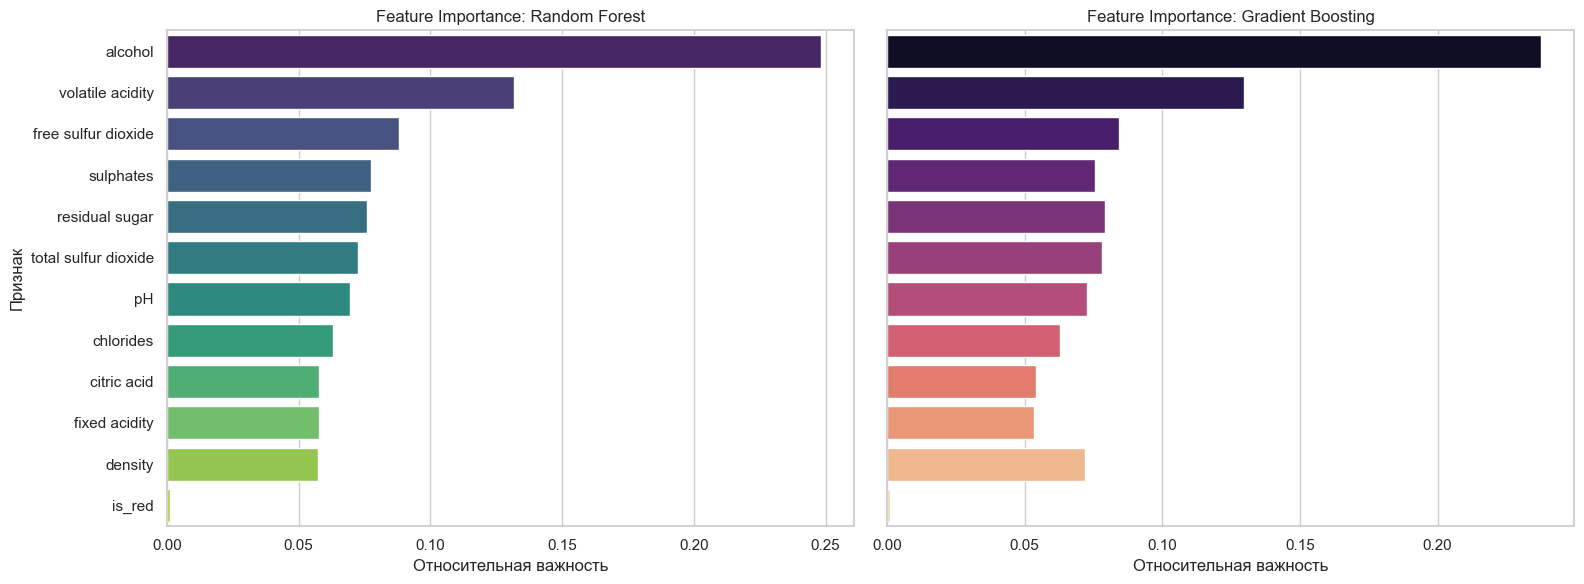

In [8]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
).fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
evaluate_model('Random Forest', y_test, y_pred_rf)

gb_model = GradientBoostingRegressor(
    n_estimators=400,
    learning_rate=0.08,
    max_depth=6,
    subsample=0.85,
    random_state=RANDOM_STATE,
).fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)
evaluate_model('Gradient Boosting', y_test, y_pred_gb)

fi_df = pd.DataFrame({
    'Признак': X.columns,
    'Random Forest': rf_model.feature_importances_,
    'Gradient Boosting': gb_model.feature_importances_,
    'Linear Regression (|coef| norm)': (
        np.abs(lr_simple.coef_) / np.sum(np.abs(lr_simple.coef_))
    ),
}).sort_values(by='Random Forest', ascending=False)

display(fi_df)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
sns.barplot(
    data=fi_df, x='Random Forest', y='Признак', ax=axes[0], palette='viridis'
)
axes[0].set_title('Feature Importance: Random Forest')
axes[0].set_xlabel('Относительная важность')

sns.barplot(
    data=fi_df, x='Gradient Boosting', y='Признак', ax=axes[1], palette='magma'
)
axes[1].set_title('Feature Importance: Gradient Boosting')
axes[1].set_xlabel('Относительная важность')
plt.tight_layout()
plt.show()

### Выводы по Feature Importance и ответ на теоретический вопрос:
1. **Сравнение важности признаков между моделями и EDA:**
   * И в `Random Forest`, и в `Gradient Boosting` два главных признака полностью совпадают между собой и с выводами EDA / линейной регрессии: 1-е место занимает **`alcohol`** (~24–25% всей важности), 2-е место — **`volatile acidity`** (~13% важности).
   * На 3-е место обе деревянные модели ставят **`free sulfur dioxide`** (~8.5–9%), тогда как в линейной регрессии его вес был мал. Причина в том, что влияние диоксида серы существенно нелинейно (при слишком низком значении вино окисляется, при слишком высоком — появляется резкий сернистый запах), и деревья решений легко улавливают этот оптимум разбиениями по порогам.
2. **Можно ли на основании feature importance утверждать, что изменение данного признака является причиной изменения качества вина? Почему?**
   * **Нет, нельзя.** Значения `feature importance` отражают лишь **статистическую связь (корреляцию)** признака с предсказаниями модели на наблюдаемых данных, но не доказывают **причинно-следственную связь. Например, высокая важность `alcohol` не означает, что прямое добавление этилового спирта в бутылку вина повысит его оценку у сомелье. За этим признаком стоят скрытые смешивающие факторы (конфаундеры): спелость винограда, количество солнечных дней и технология брожения, которые одновременно повышают градус и формируют богатый вкусовой букет.

## 6. Честное сравнение моделей

Сравним все четыре модели на единой тестовой выборке.

In [9]:
order = ['Baseline', 'Linear Regression', 'Random Forest', 'Gradient Boosting']
results_df = (
    pd.DataFrame(results)
    .T.loc[order]
    .reset_index()
    .rename(columns={'index': 'Модель'})
)
display(results_df.round(4))

,Модель,RMSE,MAE
0,Baseline,0.8738,0.6861
1,Linear Regression,0.6790,0.5291
2,Random Forest,0.6060,0.4303
3,Gradient Boosting,0.6102,0.4366


### Сравнение результатов и причины различий:
1. **Превосходство над Baseline:** Все три содержательные модели (`Linear Regression`, `Random Forest`, `Gradient Boosting`) существенно превзошли тривиальный `Baseline` ($RMSE = 0.8738$) и уложились в целевой норматив лабораторной работы **$RMSE < 0.70$**.
2. **Причины преимущества ансамблей деревьев (`Random Forest`: $0.6060$, `Gradient Boosting`: $0.6102$) над полиномиальной линейной регрессией ($0.6834$):**
   * **Локальные пороговые зависимости:** Вкус вина определяется сложным балансом компонентов (кислотность/сахар/алкоголь). Деревья решений делят пространство признаков на локальные гиперпрямоугольники, что позволяет им изолировать удачные сочетания физико-химических параметров лучше, чем глобальная полиномиальная функция.
   * **Устойчивость к выбросам и мультиколлинеарности:** Деревянные модели нечувствительны к сильной корреляции между плотностью, сахаром и алкоголем, а также к экстремальным значениям диоксида серы.
   * `Random Forest` показал минимальный RMSE (`0.6060`) за счет усреднения ответов 300 глубоких деревьев, что эффективно гасит дисперсию прогнозов на сложных граничных объектах.

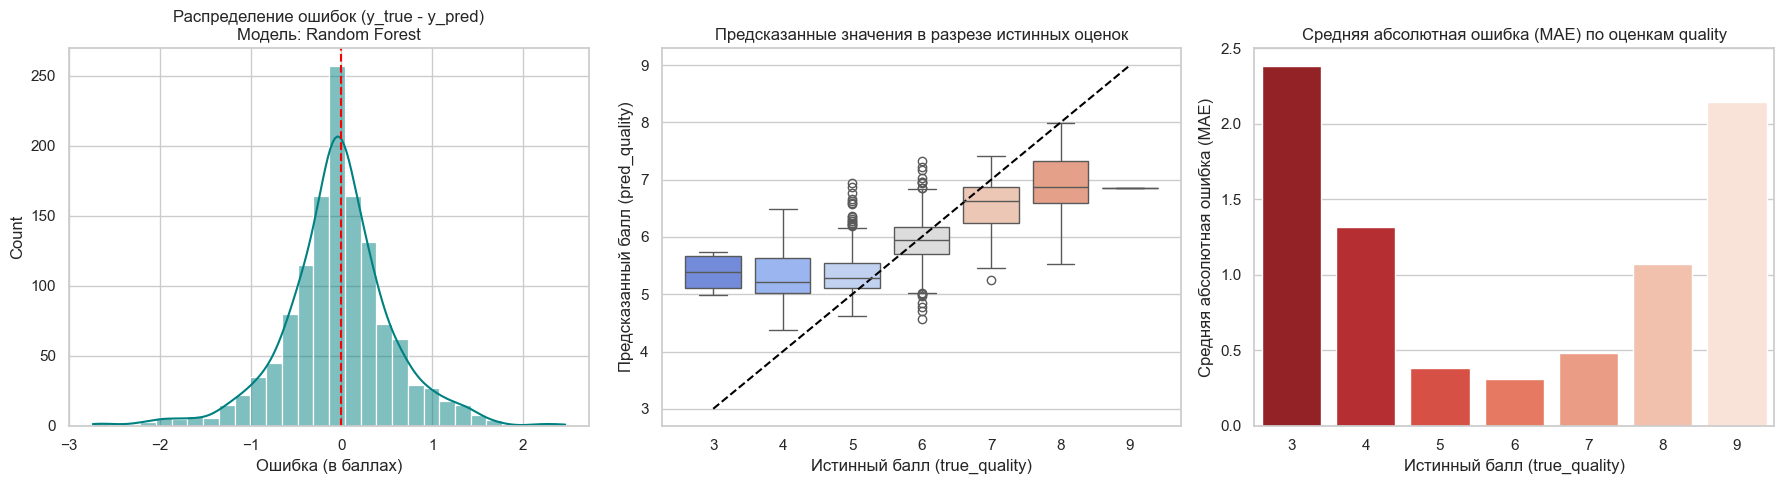

Топ-5 объектов тестовой выборки с наибольшей абсолютной ошибкой:


,alcohol,volatile acidity,free sulfur dioxide,is_red,true_quality,pred_quality,error,abs_error
2339,12.6,0.39,5.0,0,3,5.740000,-2.740000,2.740000
3287,9.4,0.25,118.5,0,3,5.700000,-2.700000,2.700000
1850,9.8,0.26,41.0,0,3,5.606667,-2.606667,2.606667
6107,11.5,0.26,75.0,0,4,6.493333,-2.493333,2.493333
3005,10.5,0.22,12.0,0,8,5.533333,2.466667,2.466667


In [10]:
analysis_df = X_test.copy()
analysis_df['true_quality'] = y_test.values
analysis_df['pred_quality'] = y_pred_rf
analysis_df['error'] = analysis_df['true_quality'] - analysis_df['pred_quality']
analysis_df['abs_error'] = np.abs(analysis_df['error'])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(analysis_df['error'], kde=True, bins=30, ax=axes[0], color='teal')
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_title(
    'Распределение ошибок (y_true - y_pred)\nМодель: Random Forest'
)
axes[0].set_xlabel('Ошибка (в баллах)')

sns.boxplot(
    data=analysis_df,
    x='true_quality',
    y='pred_quality',
    ax=axes[1],
    palette='coolwarm',
)
axes[1].plot(
    range(0, 7),
    range(3, 10),
    color='black',
    linestyle='--',
    label='Идеальное совпадение',
)
axes[1].set_title('Предсказанные значения в разрезе истинных оценок')
axes[1].set_xlabel('Истинный балл (true_quality)')
axes[1].set_ylabel('Предсказанный балл (pred_quality)')

mae_by_class = (
    analysis_df.groupby('true_quality')['abs_error'].mean().reset_index()
)
sns.barplot(
    data=mae_by_class,
    x='true_quality',
    y='abs_error',
    ax=axes[2],
    palette='Reds_r',
)
axes[2].set_title('Средняя абсолютная ошибка (MAE) по оценкам quality')
axes[2].set_xlabel('Истинный балл (true_quality)')
axes[2].set_ylabel('Средняя абсолютная ошибка (MAE)')

plt.tight_layout()
plt.show()

print('Топ-5 объектов тестовой выборки с наибольшей абсолютной ошибкой:')
worst_predictions = analysis_df.sort_values(by='abs_error', ascending=False).head(5)
display(
    worst_predictions[[
        'alcohol',
        'volatile acidity',
        'free sulfur dioxide',
        'is_red',
        'true_quality',
        'pred_quality',
        'error',
        'abs_error',
    ]]
)

### Выводы по анализу ошибок:
1. **Распределение остатков:** Гистограмма ошибок симметрична с центром в `0.0`, что говорит об отсутствии глобального смещения модели. Большинство ошибок укладываются в диапазон $\pm 0.5$ балла.
2. **Неравномерность качества по разным значениям `quality`:**
   * Для частых классов (**5, 6 и 7 баллов**) модель работает отлично: средняя абсолютная ошибка составляет всего $0.31\text{–}0.48$ балла.
   * На редких экстремальных классах (**3, 4** и **8, 9 баллов**) ошибка резко возрастает до **$1.1\text{–}2.4$ балла**. При этом для плохих вин (3–4 балла) модель систематически завышает оценку (предсказывает 5.2–5.7), а для лучших вин (8–9 баллов) — занижает (предсказывает около 6.8–7.0).
3. **Анализ объектов с самыми крупными ошибками:**
   * Например, объект с индексом `2339` (белое вино, `true_quality = 3`, `pred_quality = 5.74`, ошибка `-2.74` балла) имеет высокий процент алкоголя (`12.6%`) и умеренную летучую кислотность (`0.39`), что типично для хороших вин, но при этом крайне низкий уровень свободного $SO_2$ (`5.0`), из-за чего вино могло окислиться и испортиться.
   * Объект `3287` (`true_quality = 3`, `pred_quality = 5.70`) наоборот имеет экстремальный выброс по свободному диоксиду серы (`118.5`), либо дегустаторы снизили балл за дефекты, которые не отражены в 11 базовых физико-химических признаках.
4. **Почему модель хуже предсказывает редко встречающиеся значения `quality`?**
   * **Острый дефицит обучающих примеров:** В обучающей выборке всего 4 примера с оценкой 9 и 24 примера с оценкой 3 на 5197 строк. Деревьям просто не хватает объектов для формирования надежных правил на краях распределения.
   * **Сглаживание предсказаний к среднему:** Алгоритм минимизирует квадратичную функцию потерь MSE на выборке, где 75% ответов равны 5 или 6, а предсказание `Random Forest` является усреднением по 300 деревьям, что математически сжимает диапазон ответов к центру распределения.